In [ ]:
import numpy as np
import pandas as pd
from astropy.io import fits
from astropy.table import Table
# import os

path = '../data/raw/Multiwave_6_12_26.fits'

with fits.open(path) as hdul:
    table = Table(hdul[1].data)
    df = table.to_pandas()

df = df.loc[:, ~df.columns.str.startswith("Unnamed")]
df = df.set_index('name')
df = df.rename({'IR_agn': 'ir_agn'}, axis=1)

display(df.shape)


# Treating ' ' as NaN
object_cols = df.select_dtypes(include='object').columns

df[object_cols] = df[object_cols].astype('string').apply(lambda col: col.str.strip())
df[object_cols] = df[object_cols].replace("", np.nan)



# List of columns by dtype
for i in df.dtypes.unique():
    print(f'Columns with {i} dtype:', df.select_dtypes(include=i).columns.tolist())

# Missing value proportion DataFrame
missing = pd.DataFrame({
    'NaN perc': (df.isna().sum() / df.shape[0] * 100).round(2), 
    'missing cnt': df.isna().sum(), 
    'non-missing cnt': df.notna().sum(),
    }).sort_values('NaN perc', ascending=False)

for i in range(0, 100, 25):
    print(f'Columns with NaN values percentage between {i} and {i + 25}: ', end="") 
    print(missing[(missing['NaN perc'] >= i) & 
          (missing['NaN perc'] < i + 25)].shape[0])

missing

(166557, 163)

C:\Users\I\AppData\Local\Temp\ipykernel_32520\2158509398.py:21: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  object_cols = df.select_dtypes(include='object').columns


Columns with int32 dtype: ['col1']
Columns with float64 dtype: ['ra', 'dec', 'gal_l', 'gal_b', 'err_ellipse_r0', 'err_ellipse_r1', 'err_ellipse_ang', 'significance', 'flux_aper_b', 'flux_aper_lolim_b', 'flux_aper_hilim_b', 'flux_aper_h', 'flux_aper_lolim_h', 'flux_aper_hilim_h', 'flux_aper_m', 'flux_aper_lolim_m', 'flux_aper_hilim_m', 'flux_aper_s', 'flux_aper_lolim_s', 'flux_aper_hilim_s', 'flux_aper_u', 'flux_aper_lolim_u', 'flux_aper_hilim_u', 'flux_aper_w', 'flux_aper_lolim_w', 'flux_aper_hilim_w', 'hard_hm', 'hard_hm_lolim', 'hard_hm_hilim', 'var_inter_hard_prob_hm', 'var_inter_hard_sigma_hm', 'hard_hs', 'hard_hs_lolim', 'hard_hs_hilim', 'var_inter_hard_prob_hs', 'var_inter_hard_sigma_hs', 'hard_ms', 'hard_ms_lolim', 'hard_ms_hilim', 'var_inter_hard_prob_ms', 'var_inter_hard_sigma_ms', 'var_intra_index_b', 'var_intra_index_h', 'var_intra_index_m', 'var_intra_index_s', 'var_intra_index_u', 'var_intra_index_w', 'var_inter_index_b', 'var_inter_index_h', 'var_inter_index_m', 'var_inte

,NaN perc,missing cnt,non-missing cnt
AGNDB_e_phot_Z,100.00,166557,0
AGNDB_e_Z,100.00,166557,0
AGNDB_rf20,100.00,166557,0
AGNDB_rf6,99.99,166541,16
AGNDB_image_class,99.95,166480,77
...,...,...,...
dec,0.00,0,166557
err_ellipse_r1,0.00,0,166557
xray_agn,0.00,0,166557
optical_agn,0.00,0,166557


In [2]:
# Statistical info about NaN values inside rows
missing_rows = df.isna().sum(axis=1)/df.shape[1] * 100
display(missing_rows.describe())


# Distribution of NaN percentages inside rows
print('Missing row distribution:')

for i in range(0, 100, 10):
    row_cnt = ((missing_rows >= i) & (missing_rows < i + 10)).sum()
    perc = row_cnt / df.shape[0] * 100
    print(f'Percentage of rows with missing values between {i} and {i + 10}: ', round(perc, 5))

count    166557.000000
mean         61.331681
std          13.289192
min           7.361963
25%          57.055215
50%          64.417178
75%          69.938650
max          88.957055
dtype: float64

Missing row distribution:
Percentage of rows with missing values between 0 and 10:  0.06004
Percentage of rows with missing values between 10 and 20:  1.2206
Percentage of rows with missing values between 20 and 30:  3.85934
Percentage of rows with missing values between 30 and 40:  4.21117
Percentage of rows with missing values between 40 and 50:  5.73677
Percentage of rows with missing values between 50 and 60:  16.53848
Percentage of rows with missing values between 60 and 70:  45.83356
Percentage of rows with missing values between 70 and 80:  22.07533
Percentage of rows with missing values between 80 and 90:  0.46471
Percentage of rows with missing values between 90 and 100:  0.0


In [3]:
agn_cols = ["xray_agn", "optical_agn", "ir_agn"]

for col in agn_cols:
    if col in df.columns:
        print("\n")
        print(df[col].value_counts(dropna=False))

"""
for col in agn_cols:
    if col not in df.columns:
        print(f"Warning: {col} not found")
"""

df["agn_class"] = (
    df["xray_agn"].fillna(False).astype(bool) |
    df["optical_agn"].fillna(False).astype(bool) |
    df["ir_agn"].fillna(False).astype(bool)
)

print("\n", df["agn_class"].value_counts(dropna=False))



xray_agn
False    145394
True      21163
Name: count, dtype: int64


optical_agn
False    153066
True      13491
Name: count, dtype: int64


ir_agn
False    158636
True       7921
Name: count, dtype: int64

 agn_class
False    144935
True      21622
Name: count, dtype: int64


In [4]:
exclude_cols = [
    "name",
    "col1",
    "ra",
    "dec",
    "gal_l",
    "gal_b",
    
    "xray_agn",
    "optical_agn",
    "ir_agn",
    "agn_class",
    
    "likelihood_class",
    "SDSS_CLASS",
    "SDSS_SUBCLASS",
    "2MASS21P_designation"
]

exclude_cols = [c for c in exclude_cols if c in df.columns]

X = df.drop(columns=exclude_cols, errors="ignore")
X = X.select_dtypes(include=[np.number]).copy()

print(X.shape)
display(X.head())

(166557, 137)


,err_ellipse_r0,err_ellipse_r1,err_ellipse_ang,significance,flux_aper_b,flux_aper_lolim_b,flux_aper_hilim_b,flux_aper_h,flux_aper_lolim_h,flux_aper_hilim_h,...,AGNDB_q_Z,AGNDB_min_phot_Z,AGNDB_max_phot_Z,AGNDB_p_phot_Z,AGNDB_best_Z,AGNDB_e_best_Z,AGNDB_f_best_Z,AGNDB_rf5,AGNDB_rf6,Rec_Z
name,,,,,,,,,,,,,,,,,,,,,
2CXO_J122734.8+752428,0.448858,0.401369,117.360884,3.0,0.0,0.0,2.343371e-15,0.0,0.0,2.265900e-15,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2CXO_J015849.8-341338,0.871104,0.505601,92.776679,3.0,0.0,0.0,4.825130e-15,0.0,0.0,4.991575e-15,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2CXO_J233119.3+000805,1.618349,0.757823,42.646731,3.0,0.0,0.0,7.358777e-15,0.0,0.0,8.831036e-15,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2CXO_J101059.0-044641,1.245511,0.759778,36.915756,3.0,0.0,0.0,3.917044e-14,0.0,0.0,2.213169e-14,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2CXO_J095515.0+693614,1.884902,1.204696,48.475417,3.0,0.0,0.0,5.025451e-15,0.0,0.0,2.471392e-15,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
feature_missing_percent = X.isna().mean() * 100

display(
    feature_missing_percent.sort_values(ascending=False).head(10)
)

max_feature_missing = 90

keep_cols = feature_missing_percent[feature_missing_percent <= max_feature_missing].index
X = X[keep_cols].copy()

print(X.shape)

AGNDB_rf6            99.990394
AGNDB_rf5            99.742431
var_inter_index_w    99.325156
flux_aper_w          98.991336
flux_aper_lolim_w    98.991336
flux_aper_hilim_w    98.991336
var_intra_index_w    98.539239
AGNDB_e_spec_Z       97.765930
AGNDB_e_best_Z       97.765930
AGNDB_spec_Z         97.245387
dtype: float64

(166557, 110)


In [13]:
# Imputing and encoding the missing data
from sklearn.impute import SimpleImputer

sample_size = len(df) # we can adjust 

df_sample = df.sample(
    n=min(sample_size, len(df)),
    random_state=42
).sort_index().copy()

X_sample = X.loc[df_sample.index].copy()

print(df_sample.shape)
print(X_sample.shape)

missing_indicators = X_sample.isna().astype("int8")
missing_indicators.columns = [f"{col}_missing" for col in X_sample.columns]

imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(X_sample)


X_umap_input = np.hstack([
    X_imputed,
    missing_indicators.values
]).astype("float32")

print(X_umap_input.shape)

(166557, 164)
(166557, 110)
(166557, 220)


In [14]:
# PCA before UMAP
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_umap_input).astype("float32")

n_pca = min(30, X_scaled.shape[1])

pca = PCA(n_components=n_pca, random_state=42)
X_pca = pca.fit_transform(X_scaled).astype("float32")

print(X_pca.shape)
print("Explained variance:", pca.explained_variance_ratio_.sum())

(166557, 30)
Explained variance: 0.8134476


In [15]:
# UMAP
import umap

reducer = umap.UMAP(
    n_neighbors=15,
    min_dist=0.1,
    n_components=2,
    metric="euclidean",
    random_state=42,
    n_jobs=-1,
    low_memory=True
)

embedding = reducer.fit_transform(X_pca)

print(embedding.shape)

umap_df = pd.DataFrame(
    {
        "UMAP1": embedding[:, 0],
        "UMAP2": embedding[:, 1]
    },
    index=df_sample.index
)

umap_df["agn_class"] = df_sample["agn_class"].values
umap_df["NaN_percent"] = df_sample.isna().mean(axis=1).values * 100

display(umap_df.head())

c:\Users\I\miniforge3\envs\quant\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


(166557, 2)


,UMAP1,UMAP2,agn_class,NaN_percent
name,,,,
2CXO_J000000.0+004331,-2.479768,9.524352,False,38.414634
2CXO_J000000.3+321702,17.360617,-3.343148,False,68.902439
2CXO_J000000.5-575830,19.002634,0.188156,False,67.073171
2CXO_J000001.5-245151,15.095118,11.846608,False,74.390244
2CXO_J000001.7+003824,17.487026,-3.786923,False,68.292683


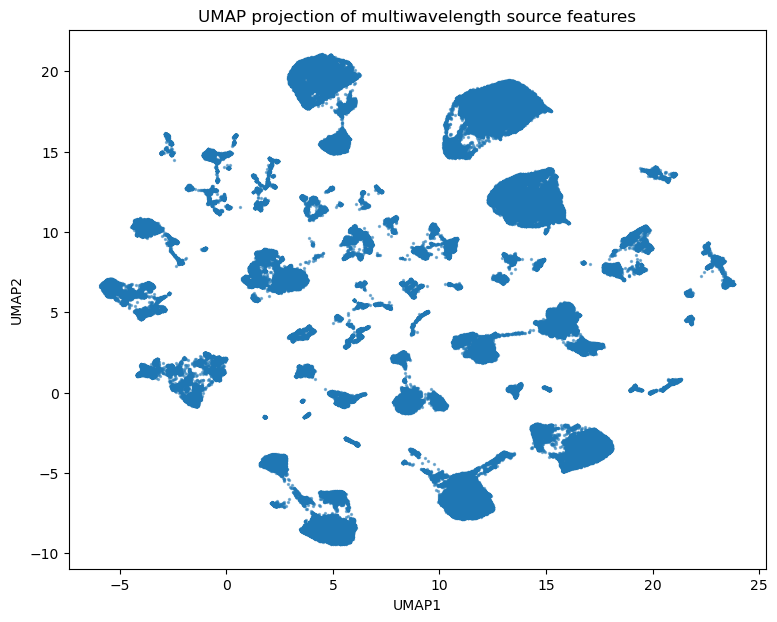

In [16]:
# Plotting UMAP
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 7))

plt.scatter(
    umap_df["UMAP1"],
    umap_df["UMAP2"],
    s=2,
    alpha=0.5
)

plt.xlabel("UMAP1")
plt.ylabel("UMAP2")
plt.title("UMAP projection of multiwavelength source features")
plt.show()

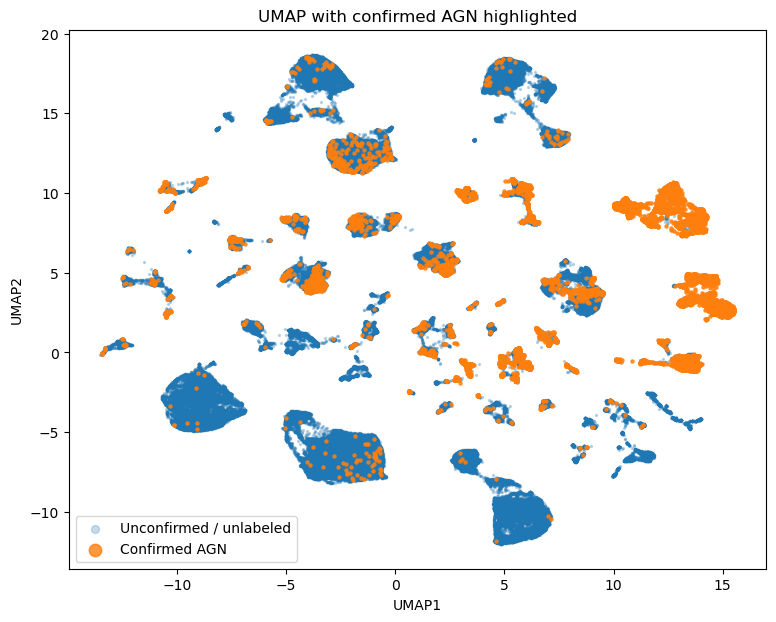

In [10]:
plt.figure(figsize=(9, 7))
mask_agn = umap_df["agn_class"] == True

plt.scatter(
    umap_df.loc[~mask_agn, "UMAP1"],
    umap_df.loc[~mask_agn, "UMAP2"],
    s=2,
    alpha=0.25,
    label="Unconfirmed / unlabeled"
)

plt.scatter(
    umap_df.loc[mask_agn, "UMAP1"],
    umap_df.loc[mask_agn, "UMAP2"],
    s=5,
    alpha=0.8,
    label="Confirmed AGN"
)

plt.xlabel("UMAP1")
plt.ylabel("UMAP2")
plt.title("UMAP with confirmed AGN highlighted")
plt.legend(markerscale=4)
plt.show()

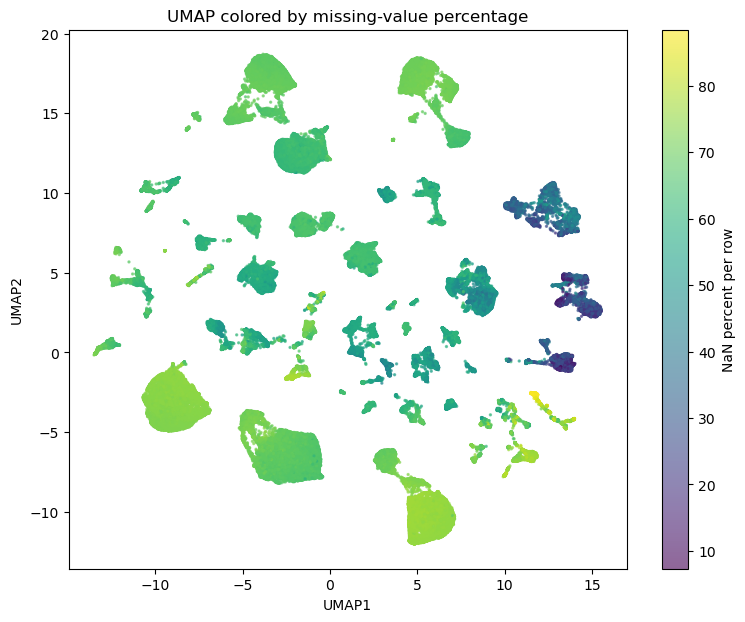

In [11]:
plt.figure(figsize=(9, 7))

plt.scatter(
    umap_df["UMAP1"],
    umap_df["UMAP2"],
    c=umap_df["NaN_percent"],
    s=2,
    alpha=0.6
)

plt.colorbar(label="NaN percent per row")
plt.xlabel("UMAP1")
plt.ylabel("UMAP2")
plt.title("UMAP colored by missing-value percentage")
plt.show()

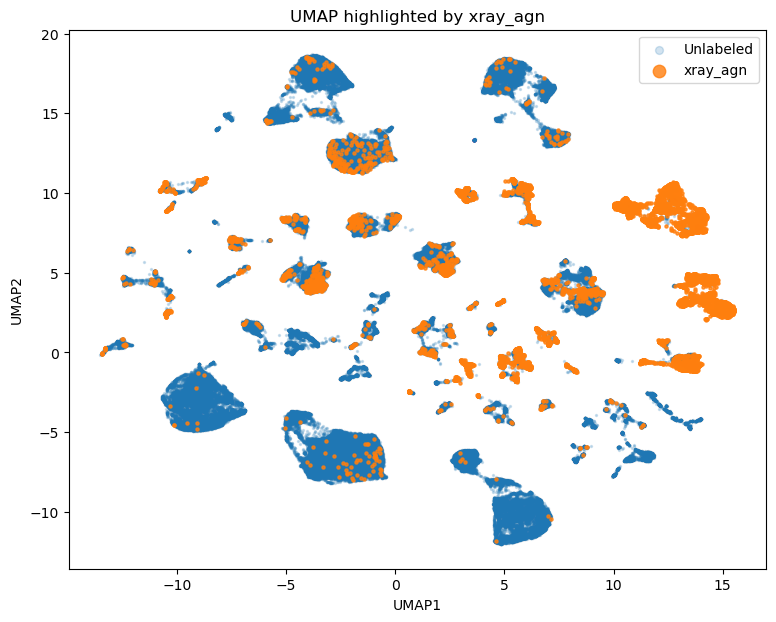

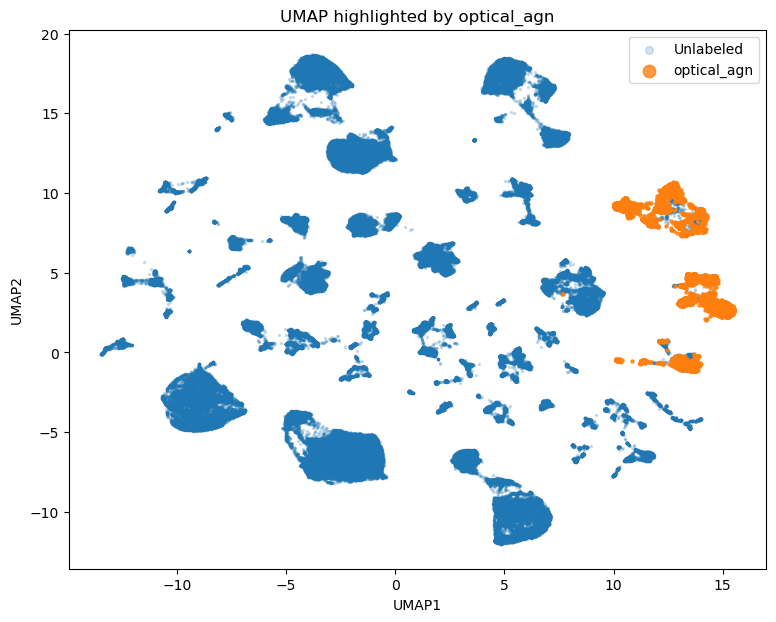

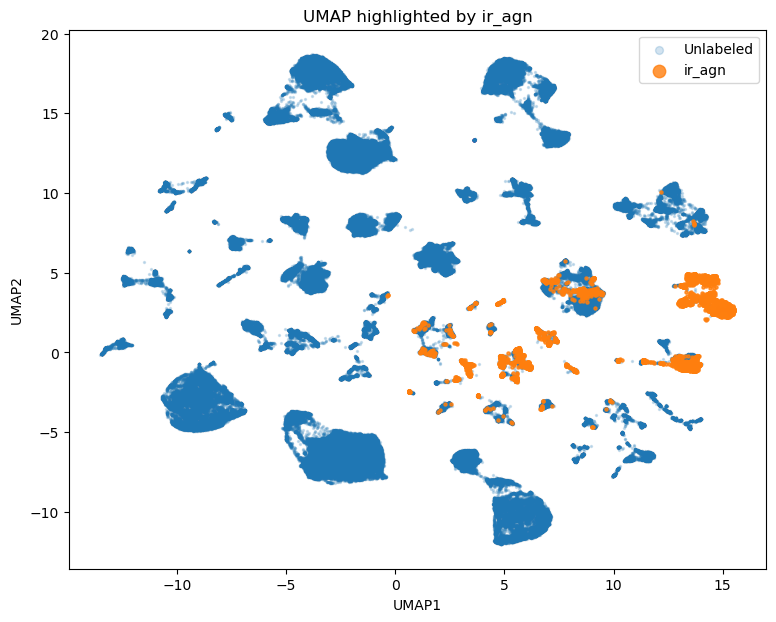

In [12]:
for label_col in ["xray_agn", "optical_agn", "ir_agn"]:
    if label_col in df_sample.columns:
        label_values = df_sample[label_col].fillna(False).astype(bool)
        
        plt.figure(figsize=(9, 7))
        
        plt.scatter(
            umap_df.loc[~label_values, "UMAP1"],
            umap_df.loc[~label_values, "UMAP2"],
            s=2,
            alpha=0.2,
            label="Unlabeled"
        )
        
        plt.scatter(
            umap_df.loc[label_values, "UMAP1"],
            umap_df.loc[label_values, "UMAP2"],
            s=5,
            alpha=0.8,
            label=label_col
        )
        
        plt.xlabel("UMAP1")
        plt.ylabel("UMAP2")
        plt.title(f"UMAP highlighted by {label_col}")
        plt.legend(markerscale=4)
        plt.show()